In [1]:
import hashlib
import os
import platform
import uuid
STUDENT_ID = 20244080325
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]       {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")

[Conda 环境] hw01
[学号]       20244080325
[机器指纹] 1f5f361f891f3218
[RUN_ID]   20244080325-1f5f361f891f3218


wigner_density(0) = 0.3183098861837907
wigner_density(2) = 0.27566444771089604
generate_wigner(3) 形状: (3, 3)  对称: True
ValueError: n 必须是正整数
get_spectrum 例子: [-1.  1.]


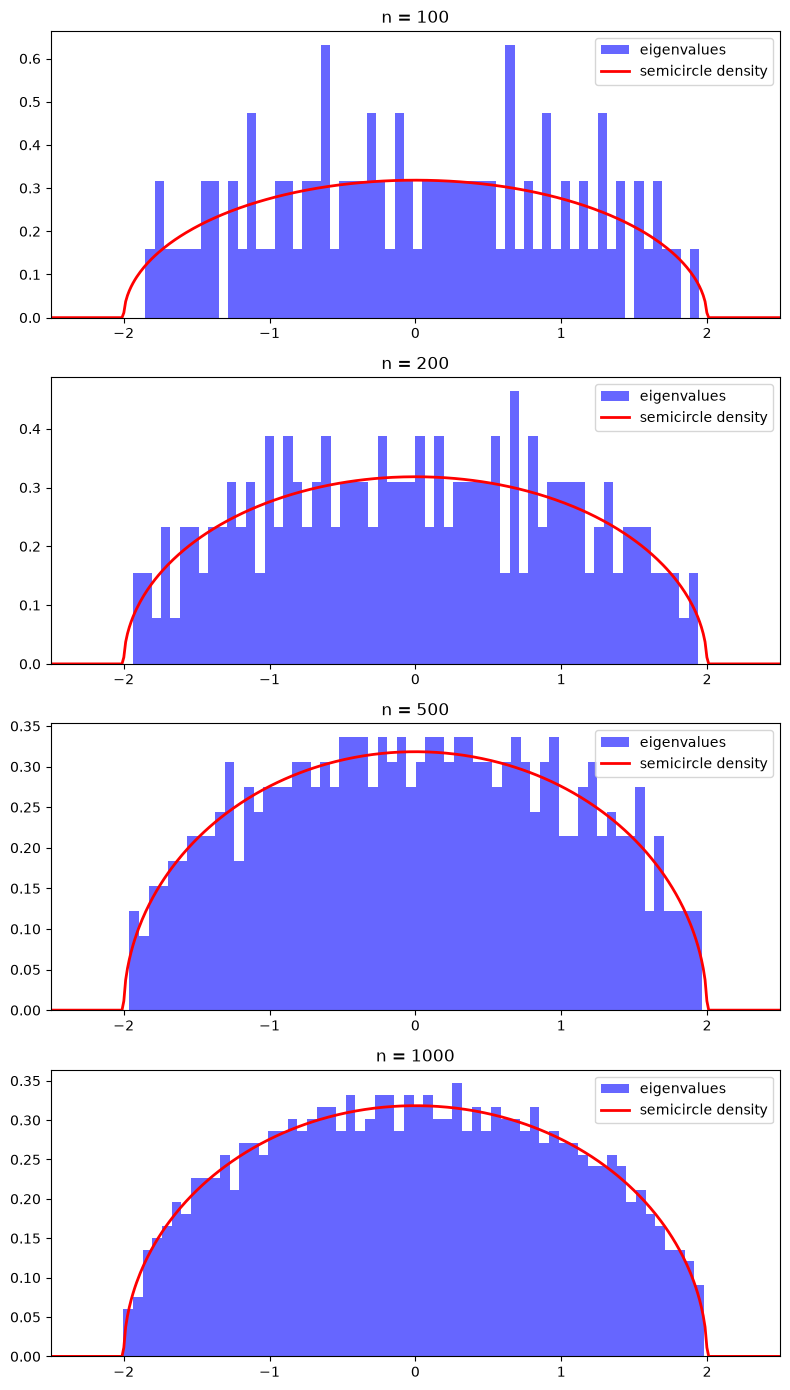

In [5]:
import numpy as np
import matplotlib.pyplot as plt

def wigner_density(x):
    x = np.asarray(x, dtype=float)
    d = np.where(np.abs(x) <= 2, np.sqrt(np.maximum(4 - x**2, 0)) / (2 * np.pi), 0.0)
    return float(d) if d.ndim == 0 else d

print("wigner_density(0) =", wigner_density(0))
print("wigner_density(2) =", wigner_density(1))

def generate_wigner(n):
    if not isinstance(n, (int, np.integer)) or isinstance(n, bool):
        raise TypeError("n 必须是整数")
    if n <= 0:
        raise ValueError("n 必须是正整数")
    A = np.random.normal(0, 1 / np.sqrt(n), size=(n, n))
    return np.triu(A) + np.triu(A, k=1).T

Z = generate_wigner(3)
print("generate_wigner(3) 形状:", Z.shape, " 对称:", np.allclose(Z, Z.T))
try:
    generate_wigner(0)
except ValueError as e:
    print("ValueError:", e)

def get_spectrum(matrix):
    return np.sort(np.linalg.eigvalsh(np.asarray(matrix)))

print("get_spectrum 例子:", get_spectrum(np.array([[0, 1], [1, 0]], dtype=float)))

np.random.seed(0)
ns = [100, 200, 500, 1000]
x = np.linspace(-2.5, 2.5, 400)
fig, axes = plt.subplots(4, 1, figsize=(8, 14))
for ax, n in zip(axes, ns):
    Z = generate_wigner(n)
    eigs = get_spectrum(Z)
    ax.hist(eigs, bins=60, density=True, color="blue", alpha=0.6, label="eigenvalues")
    ax.plot(x, wigner_density(x), color="red", linewidth=2, label="semicircle density")
    ax.set_title(f"n = {n}")
    ax.set_xlim(-2.5, 2.5)
    ax.legend()
plt.tight_layout()
plt.show()

True
False
[[1 1 0 0]
 [1 1 1 1]
 [1 1 0 0]
 [0 0 0 1]]


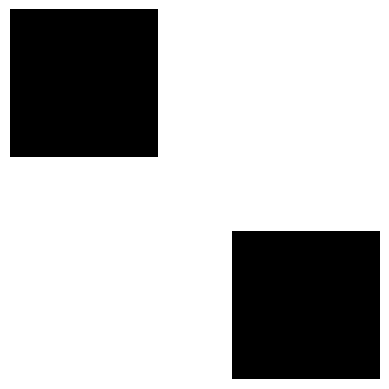

In [3]:
import numpy as np
import matplotlib.pyplot as plt

def is_valid_board(board):
    if not isinstance(board, np.ndarray):
        return False
    if board.ndim != 2:
        return False
    return bool(np.isin(board, [0, 1]).all())

print(is_valid_board(np.array([[0, 1], [1, 0]])))   
print(is_valid_board(np.array([[0, 2], [-2, 0]])))   

def gol_step(board):
    if not is_valid_board(board):
        raise ValueError("无效棋盘：必须是二维 ndarray，元素仅为 0/1")
    m, n = board.shape
    neighbors = np.zeros_like(board, dtype=int)
    for di in (-1, 0, 1):
        for dj in (-1, 0, 1):
            if di == 0 and dj == 0:
                continue
            neighbors += np.roll(np.roll(board, di, axis=0), dj, axis=1)
    new_board = np.zeros_like(board)
    new_board[(board == 1) & ((neighbors == 2) | (neighbors == 3))] = 1
    new_board[(board == 0) & (neighbors == 3)] = 1
    return new_board

tt = np.array([[1, 0, 0, 0],
                  [0, 1, 1, 1],
                  [0, 0, 1, 0],
                  [0, 0, 0, 1]], dtype=int)
print(gol_step(tt))

def draw_gol_board(board):
    plt.imshow(board, cmap=plt.get_cmap("gray_r"), interpolation="nearest")
    plt.xticks([])
    plt.yticks([])
    plt.axis("off")
    plt.show()

ss = np.array([[1, 1, 0, 0, 0],
                  [1, 1, 0, 0, 0],
                  [0, 0, 0, 0, 0],
                  [0, 0, 0, 1, 1],
                  [0, 0, 0, 1, 1]], dtype=int)
draw_gol_board(ss)

In [4]:
import pandas as pd

df = pd.read_csv("iris.csv")
print("列名:", list(df.columns))
print("数据点数量:", len(df))
print("各列数据类型:\n", df.dtypes)
print("花卉种类:", df["Species"].unique())

df.iloc[34, 1:5] = [4.9, 3.1, 1.5, 0.2]
df.iloc[34, 5] = "Iris-setosa"
df.iloc[37, 1:5] = [4.9, 3.6, 1.4, 0.1]
df.iloc[37, 5] = "Iris-setosa"
print("\n修正后的两行:\n", df.iloc[[34, 37]])

df["Petal.Ratio"] = df["PetalLengthCm"] / df["PetalWidthCm"]
df["Sepal.Ratio"] = df["SepalLengthCm"] / df["SepalWidthCm"]
print("\n新增列示例:\n", df[["Petal.Ratio", "Sepal.Ratio"]].head())

df.to_csv("iris_corrected.csv", index=False)
print("\n已保存 iris_corrected.csv，形状:", df.shape)

agg = df.groupby("Species")[["Petal.Ratio", "Sepal.Ratio"]].agg(
    ["mean", "median", "min", "max", "std"]
)
print("\n分组聚合结果:\n", agg)

列名: ['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']
数据点数量: 150
各列数据类型:
 Id                 int64
SepalLengthCm    float64
SepalWidthCm     float64
PetalLengthCm    float64
PetalWidthCm     float64
Species              str
dtype: object
花卉种类: <StringArray>
['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
Length: 3, dtype: str

修正后的两行:
     Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
34  35            4.9           3.1            1.5           0.2  Iris-setosa
37  38            4.9           3.6            1.4           0.1  Iris-setosa

新增列示例:
    Petal.Ratio  Sepal.Ratio
0          7.0     1.457143
1          7.0     1.633333
2          6.5     1.468750
3          7.5     1.483871
4          7.0     1.388889

已保存 iris_corrected.csv，形状: (150, 8)

分组聚合结果:
                 Petal.Ratio                                     Sepal.Ratio  \
                       mean    median       min   max       std        mean   
Species